# Toric code

This notebook demonstrates GFMC for Kitaev's toric code on an $L_x \times L_y$ torus:

$$H = -A_s \sum_{v} \prod_{i \in \text{star}(v)} \sigma^x_i
     - B_p \sum_{p} \prod_{i \in \text{plaq}(p)} \sigma^z_i
     - h_z \sum_i \sigma^z_i
     - h_x \sum_i \sigma^x_i$$

**Sites** are the $N = 2 L_x L_y$ edges of the square lattice; $n_p$ is the number of plaquettes, $n_s$ is the number of stars.

**Sign-problem-free convention**: $A_s \geq 0$, $h_x \geq 0$; $B_p$ and $h_z$ may have any sign (diagonal).  

**Exact ground-state energy** of the pure toric code ($h_z = h_x = 0$):
all star and plaquette stabilizers are simultaneously $+1$, giving
$$E_0 = -(A_s\,n_s + B_p\,n_p)$$


In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from pygfmc import run, evaluate_observables
from pygfmc.hamiltonian import ToricCode, exact_diagonalization
from pygfmc.walkers import prepare_walkers_from_configs

print(f'JAX version : {jax.__version__}')
print(f'Backend     : {jax.default_backend()}')

JAX version : 0.9.2
Backend     : cpu


## Pure toric code

We run GFMC for the pure toric code ($A_s = B_p = 1$, $h_z = h_x = 0$) on a
$10 \times 10$ torus ($200$ sites) and compare it with the exact ground-state energy
$E_0/N = -1$.

The walkers are initialized in the all-up state.

In [2]:
rng = jax.random.PRNGKey(42)
rng, k_run = jax.random.split(rng)

Lx, Ly = 10, 10

H = ToricCode.create(Lx, Ly, A_s=1.0, B_p=1.0, h_z=0.0, h_x=0.0)
E0_exact = -(1.0 * Lx * Ly + 1.0 * Lx * Ly)   # -(A_s n_s + B_p n_p): every stabilizer +1

walkers = prepare_walkers_from_configs(jnp.ones((512, H.N)))

walkers_out, energy, _, stats, raw = run(
    walkers, 5000, H, step_size=0.25,     # continuous time: imaginary time 0.25 per step
    guide=None, p_array=[2, 4, 8, 16, 32],
    rng_key=k_run, warmup_steps=500, verbosity=0,
)

for p in [2, 4, 8, 16, 32]:
    print(f'p = {p:2d}:  E/site = {energy[p] / H.N:.8f}')
print(f'exact     E/site = {E0_exact / H.N:.8f}')


p =  2:  E/site = -0.99999998
p =  4:  E/site = -0.99999995
p =  8:  E/site = -1.00000011
p = 16:  E/site = -1.00000002
p = 32:  E/site = -0.99999998
exact     E/site = -1.00000000


## Why is GFMC in *exact* (float precision) agreement here?

GFMC is exact here because the ground state is an equal superposition of all states in the same topological sector.

With no guide (equivalent to setting $\Psi_T(x) = 1$), GFMC samples the ground state perfectly. The local energy of every reachable configuration in this flux-free sector is $E_0$, so the algorithm shows no fluctuations.

The convergence also follows because the matrix is a stochastic matrix up to normalization and a diagonal shift.

## Adding fields

Including local fields breaks the solvability, and the equal superposition is no longer the ground state.

h = 0.0:  E_p/site = -1.00000, -1.00000, -1.00000, -1.00000, -1.00000, -1.00000, -1.00000   (ED -1.00000)


h = 0.125:  E_p/site = -1.00786, -1.00821, -1.00847, -1.00851, -1.00853, -1.00839, -1.00815   (ED -1.00830)


h = 0.25:  E_p/site = -1.03131, -1.03336, -1.03529, -1.03599, -1.03581, -1.03567, -1.03538   (ED -1.03705)


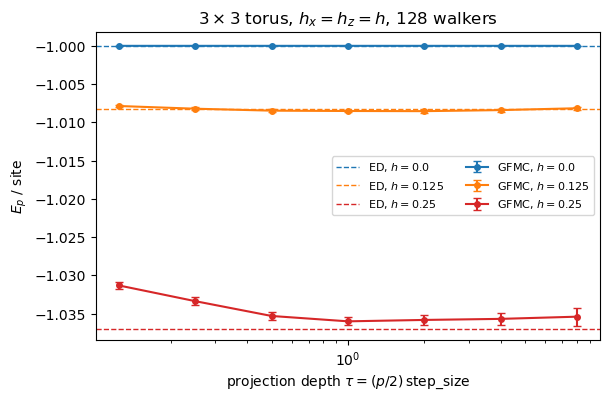

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 4))
p_eval = [1, 2, 4, 8, 16, 32, 64]
for h, color in zip([0.0, 0.125, 0.25], ['C0', 'C1', 'C3']):
    # 3x3 torus with h_x = h_z = h; exact diagonalization gives the reference
    H  = ToricCode.create(3, 3, A_s=1.0, B_p=1.0, h_x=h, h_z=h)
    E0 = float(exact_diagonalization(H, number_of_states=1)[0][0])

    # few walkers, so that the projection over the window p is visible
    rng, k_run = jax.random.split(rng)
    walkers = prepare_walkers_from_configs(jnp.ones((128, H.N)))
    _, _, _, _, raw = run(
        walkers, 20000, H, step_size=0.25,  # continuous time: imaginary time 0.25 per step
        guide=None, p_array=[2], rng_key=k_run, warmup_steps=1000, verbosity=0
    )
    E, _, E_err, _ = evaluate_observables(raw, p_array=p_eval, n_blocks=25)   # windows p after the run
    tau = np.array(p_eval) * 0.25 / 2                                         # tau = (p/2) * step_size
    ax.errorbar(tau, [E[p] / H.N for p in p_eval], [E_err[p] / H.N for p in p_eval],
                marker='o', ms=4, capsize=3, color=color, label=f'GFMC, $h = {h}$')
    ax.axhline(E0 / H.N, color=color, ls='--', lw=1, label=f'ED, $h = {h}$')
    print(f"h = {h}:  E_p/site = " + ", ".join(f"{E[p] / H.N:.5f}" for p in p_eval) + f"   (ED {E0 / H.N:.5f})")

ax.set_xscale('log')
ax.set_xlabel(r'projection depth $\tau = (p/2)\,\mathrm{step\_size}$')
ax.set_ylabel(r'$E_p$ / site')
ax.set_title(r'$3\times3$ torus, $h_x = h_z = h$, 128 walkers')
ax.legend(fontsize=8, ncol=2)
plt.show()